In [1]:
!pip install -q datasets

import pandas as pd
import numpy as np
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset = load_dataset("stanfordnlp/imdb")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

df = pd.concat([train_df, test_df], ignore_index=True)

df = df.rename(columns={
    "text": "review",
    "label": "sentiment"
})

print("Dataset loaded successfully!")
print("Total available reviews:", len(df))
print(df.head())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Total available reviews: 50000
                                              review  sentiment
0  I rented I AM CURIOUS-YELLOW from my video sto...          0
1  "I Am Curious: Yellow" is a risible and preten...          0
2  If only to avoid making this type of film in t...          0
3  This film was probably inspired by Godard's Ma...          0
4  Oh, brother...after hearing about this ridicul...          0


In [3]:
df = df[df["sentiment"].isin([0, 1])]
df = df.drop_duplicates(subset="review")

positive = df[df["sentiment"] == 1].sample(
    n=2500, random_state=42
)

negative = df[df["sentiment"] == 0].sample(
    n=2500, random_state=42
)

df = pd.concat(
    [positive, negative], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

df["label"] = df["sentiment"].astype(int)

print("Total reviews:", len(df))
print("Positive reviews:", (df["label"] == 1).sum())
print("Negative reviews:", (df["label"] == 0).sum())

Total reviews: 5000
Positive reviews: 2500
Negative reviews: 2500


In [4]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-zA-Z']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.lower().strip()

df["clean_review"] = df["review"].apply(clean_text)

print("Original review:")
print(df["review"].iloc[0][:250])

print("\nCleaned review:")
print(df["clean_review"].iloc[0][:250])

Original review:
I was so surprised by how great The Man In The Moon truly was.I mean at first I was kinda expecting a cheesy, and predictable film, but I decided to put that aside when watching.Well, when it was over I was just left stunned(mainly in tears), by how 

Cleaned review:
i was so surprised by how great the man in the moon truly was i mean at first i was kinda expecting a cheesy and predictable film but i decided to put that aside when watching well when it was over i was just left stunned mainly in tears by how great


In [5]:
X = df["clean_review"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 3500
Validation: 750
Testing: 750


In [6]:
MAX_WORDS = 10000
MAX_LEN = 200

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Vocabulary size:", min(
    len(tokenizer.word_index) + 1, MAX_WORDS
))
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)

Vocabulary size: 10000
Training shape: (3500, 200)
Validation shape: (750, 200)
Testing shape: (750, 200)


In [7]:
model = Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=8,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 24s 193ms/step - accuracy: 0.5229 - loss: 0.6921 - val_accuracy: 0.5040 - val_loss: 0.6869
Epoch 2/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 16s 149ms/step - accuracy: 0.6451 - loss: 0.6101 - val_accuracy: 0.6773 - val_loss: 0.6226
Epoch 3/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 153ms/step - accuracy: 0.8411 - loss: 0.3842 - val_accuracy: 0.7400 - val_loss: 0.5690
Epoch 4/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 159ms/step - accuracy: 0.9303 - loss: 0.1772 - val_accuracy: 0.7453 - val_loss: 0.8690
Epoch 5/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 155ms/step - accuracy: 0.9723 - loss: 0.0916 - val_accuracy: 0.7800 - val_loss: 0.8039


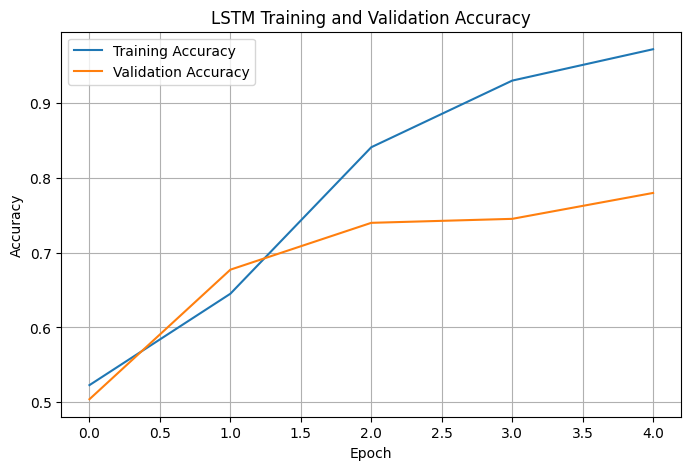

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
y_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

Accuracy  : 0.7400 (74.00%)
Precision : 0.6786
Recall    : 0.9120
F1-score  : 0.7782

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.57      0.69       375
    Positive       0.68      0.91      0.78       375

    accuracy                           0.74       750
   macro avg       0.77      0.74      0.73       750
weighted avg       0.77      0.74      0.73       750



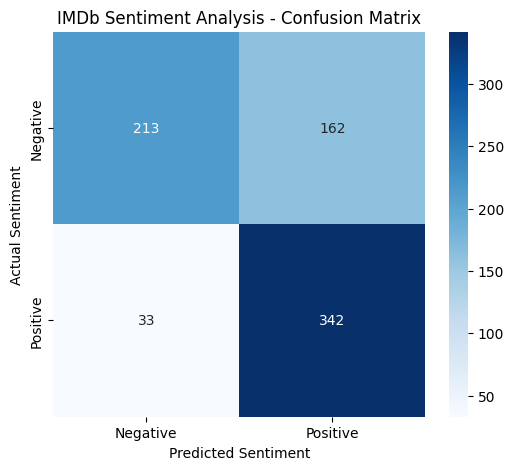

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("IMDb Sentiment Analysis - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [12]:
unseen_reviews = [
    "This movie was fantastic and the actors performed brilliantly.",
    "The film was boring and very disappointing.",
    "I loved the screenplay, music, and beautiful cinematography.",
    "A terrible movie with weak acting and a confusing plot.",
    "The movie was okay, with some good scenes but many flaws."
]

def predict_sentiment(reviews):
    cleaned = [clean_text(review) for review in reviews]

    sequences = tokenizer.texts_to_sequences(cleaned)

    padded = pad_sequences(
        sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0).ravel()

    for review, probability in zip(reviews, probabilities):
        sentiment = "Positive" if probability >= 0.5 else "Negative"

        print("\nReview:", review)
        print("Predicted sentiment:", sentiment)
        print(f"Positive probability: {probability:.4f}")

predict_sentiment(unseen_reviews)


Review: This movie was fantastic and the actors performed brilliantly.
Predicted sentiment: Positive
Positive probability: 0.8201

Review: The film was boring and very disappointing.
Predicted sentiment: Negative
Positive probability: 0.0933

Review: I loved the screenplay, music, and beautiful cinematography.
Predicted sentiment: Positive
Positive probability: 0.7541

Review: A terrible movie with weak acting and a confusing plot.
Predicted sentiment: Negative
Positive probability: 0.0270

Review: The movie was okay, with some good scenes but many flaws.
Predicted sentiment: Positive
Positive probability: 0.7578


In [13]:
import pickle

model.save("imdb_lstm_model.keras")

with open("imdb_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [14]:
print("=" * 50)
print("IMDb MOVIE REVIEW SENTIMENT ANALYSIS")
print("=" * 50)

print("Dataset size       :", len(df))
print("Training reviews   :", len(X_train))
print("Validation reviews :", len(X_val))
print("Testing reviews    :", len(X_test))

print("\nMODEL PERFORMANCE")
print("-" * 30)
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nModel type: LSTM")
print("Sentiment classes: Positive and Negative")
print("Unseen reviews tested:", 5)

print("\nPROJECT COMPLETED SUCCESSFULLY!")

IMDb MOVIE REVIEW SENTIMENT ANALYSIS
Dataset size       : 5000
Training reviews   : 3500
Validation reviews : 750
Testing reviews    : 750

MODEL PERFORMANCE
------------------------------
Accuracy  : 74.00%
Precision : 0.6786
Recall    : 0.9120
F1-score  : 0.7782

Model type: LSTM
Sentiment classes: Positive and Negative
Unseen reviews tested: 5

PROJECT COMPLETED SUCCESSFULLY!


In [15]:
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 74.00%
